# FashionMNIST Neural Network Classifier

**Name:** Milton Cruz

## Dataset Overview

- **What the dataset contains:** FashionMNIST contains 70,000 grayscale images of clothing items (60,000 for training and 10,000 for testing). Each image is 28 by 28 pixels.
- **What the input features represent:** Each input is one clothing image. The features are its 784 (28 x 28) pixel intensity values.
- **What label the network will predict:** The clothing category of the image, one of 10 classes: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot.

In [1]:
import torch
import torchvision
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

testing_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

training_loader = DataLoader(
    training_data,
    batch_size=64,
    shuffle=True
)

testing_loader = DataLoader(
    testing_data,
    batch_size=64,
    shuffle=False
)

print("Datasets loaded successfully.")
print("Training examples:", len(training_data))
print("Testing examples:", len(testing_data))

Datasets loaded successfully.
Training examples: 60000
Testing examples: 10000


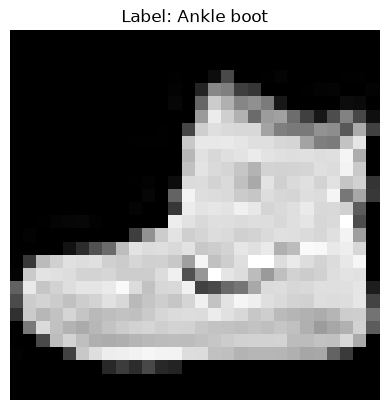

In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

image, label = training_data[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {class_names[label]}")
plt.axis("off")
plt.show()

## Transformations and Data Loaders

- **`transforms.ToTensor()`** converts each image into a PyTorch tensor of shape (1, 28, 28) and scales the pixel values from the 0-255 integer range to floats between 0.0 and 1.0.
- **Normalization:** `Normalize((0.5,), (0.5,))` shifts and scales the values to the range -1 to 1 (centered around 0). Inputs with a consistent, centered scale help the network train faster and more stably.
- **Why training data is shuffled:** Shuffling gives a different batch order each epoch, so the model does not learn from the order of the data and the batches are more representative, which improves gradient updates and generalization.
- **Why testing data is not shuffled:** Testing only measures performance, so order does not matter. Keeping a fixed order makes evaluation reproducible and results easy to compare and inspect.

In [4]:
class FashionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()  # 28x28 image -> 784 values
        self.network = nn.Sequential(
            nn.Linear(28 * 28, 128),  # input layer -> hidden layer
            nn.ReLU(),
            nn.Linear(128, 64),       # second hidden layer
            nn.ReLU(),
            nn.Linear(64, 10)         # output layer: 10 categories
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model = FashionNet()
print(model)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

FashionNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [5]:
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in training_loader:
        predictions = model(images)              # forward pass
        loss = loss_function(predictions, labels)

        optimizer.zero_grad()                    # clear previous gradients
        loss.backward()                          # calculate new gradients
        optimizer.step()                         # update parameters

        running_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs} - Training loss: {running_loss / len(training_loader):.4f}")

Epoch 1/5 - Training loss: 0.5150
Epoch 2/5 - Training loss: 0.3799
Epoch 3/5 - Training loss: 0.3429
Epoch 4/5 - Training loss: 0.3176
Epoch 5/5 - Training loss: 0.2967


In [6]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testing_loader:
        outputs = model(images)
        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

print(f"Testing accuracy: {100 * correct / total:.2f}%")

Testing accuracy: 87.29%


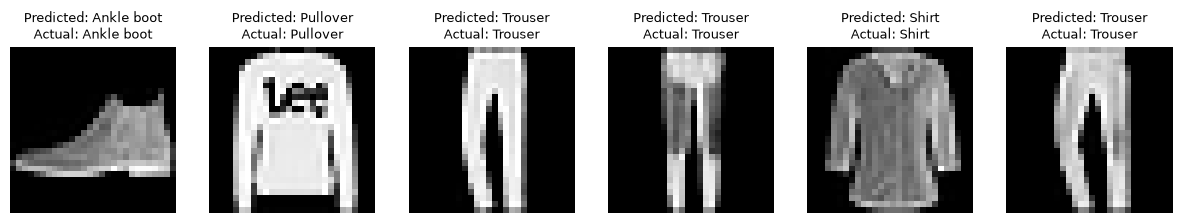

In [7]:
images, labels = next(iter(testing_loader))

with torch.no_grad():
    predicted = model(images).argmax(dim=1)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Predicted: {class_names[predicted[i]]}\nActual: {class_names[labels[i]]}", fontsize=9)
    ax.axis("off")
plt.show()